# 波士顿房价 MEDV 预测实验

本 Notebook 对 `HousingData.csv` 中的波士顿房价数据进行线性回归建模。实验严格按照题目要求：

- 模型每次只能使用 3 个特征；
- 目标变量为各区房价中位数 `MEDV`；
- 比较普通线性回归、Ridge、Lasso、ElasticNet 等线性模型，并加入正则化参数调优；
- 保留特征选择、模型选择、参数调优、评价指标和可视化分析过程。

## 1. 数据读取与预处理

先读取数据、查看字段，并检查缺失值。缺失值用训练集均值进行填充。

In [1]:
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_theme(style='whitegrid', palette='Set2')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 120)

RANDOM_STATE = 42
DATA_PATH = 'HousingData.csv'
TARGET = 'MEDV'

def rmse_score(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

raw_df = pd.read_csv(DATA_PATH)
print(f'数据集形状: {raw_df.shape}')
display(raw_df.head())

display(pd.DataFrame({
    'dtype': raw_df.dtypes,
    'missing_count': raw_df.isna().sum(),
    'missing_ratio': raw_df.isna().mean()
}))

数据集形状: (506, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,NaN,36.2


,dtype,missing_count,missing_ratio
CRIM,float64,20,0.039526
ZN,float64,20,0.039526
INDUS,float64,20,0.039526
CHAS,float64,20,0.039526
NOX,float64,0,0.000000
RM,float64,0,0.000000
AGE,float64,20,0.039526
DIS,float64,0,0.000000
RAD,int64,0,0.000000
TAX,int64,0,0.000000


## 2. 数据集划分


In [2]:
feature_names = [col for col in raw_df.columns if col != TARGET]

X_all = raw_df[feature_names]
y_all = raw_df[TARGET]

X_train_all = X_all.iloc[:400].copy()
y_train = y_all.iloc[:400].copy()

X_test_all = X_all.iloc[-100:].copy()
y_test = y_all.iloc[-100:].copy()

unused_index = raw_df.index[400:-100].tolist()

print(f'全部特征数量: {len(feature_names)}')
print(f'训练集样本数: {len(X_train_all)}，索引范围: {X_train_all.index.min()} - {X_train_all.index.max()}')
print(f'测试集样本数: {len(X_test_all)}，索引范围: {X_test_all.index.min()} - {X_test_all.index.max()}')
print(f'未使用样本索引: {unused_index}')

全部特征数量: 13
训练集样本数: 400，索引范围: 0 - 399
测试集样本数: 100，索引范围: 406 - 505
未使用样本索引: [400, 401, 402, 403, 404, 405]


## 3. 模型设计

### 3.1 模型选择与原理

本实验比较的模型都属于线性回归模型，只是正则化方式不同：

| 模型 | 原理 | 适用原因 |
|---|---|---|
| LinearRegression | 最小二乘法，最小化预测误差平方和 | 作为基础基线模型 |
| Ridge | 在线性回归基础上加入 L2 正则化 | 缓解多重共线性，降低过拟合 |
| Lasso | 加入 L1 正则化 | 可压缩不重要特征系数，增强模型稀疏性 |
| ElasticNet | 同时加入 L1 与 L2 正则化 | 兼顾 Ridge 稳定性与 Lasso 稀疏性 |

由于 Ridge / Lasso / ElasticNet 对特征尺度敏感，所以模型前加入 `StandardScaler`。缺失值处理使用 `SimpleImputer`，并封装在 `Pipeline` 中。

### 3.2 特征相关性初步分析

先只用训练集计算相关系数，避免测试集参与特征筛选。根据与 `MEDV` 的绝对相关系数，可以得到一个直观的候选特征组合。

In [3]:
train_df_for_eda = raw_df.iloc[:400].copy()
train_df_for_eda = train_df_for_eda.fillna(train_df_for_eda.mean(numeric_only=True))

corr_with_target = (
    train_df_for_eda.corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

corr_table = pd.DataFrame({
    'feature': corr_with_target.index,
    'corr_with_MEDV': corr_with_target.values,
    'abs_corr': corr_with_target.abs().values
})

display(corr_table)

corr_top_features = corr_table.head(3)['feature'].tolist()
print(f'按训练集相关性选择的 3 个特征: {corr_top_features}')

,feature,corr_with_MEDV,abs_corr
0,RM,0.752876,0.752876
1,LSTAT,-0.686163,0.686163
2,PTRATIO,-0.435450,0.435450
3,INDUS,-0.367267,0.367267
4,ZN,0.317732,0.317732
5,TAX,-0.311142,0.311142
6,NOX,-0.303358,0.303358
7,AGE,-0.288874,0.288874
8,CRIM,-0.259025,0.259025
9,RAD,-0.193685,0.193685


按训练集相关性选择的 3 个特征: ['RM', 'LSTAT', 'PTRATIO']


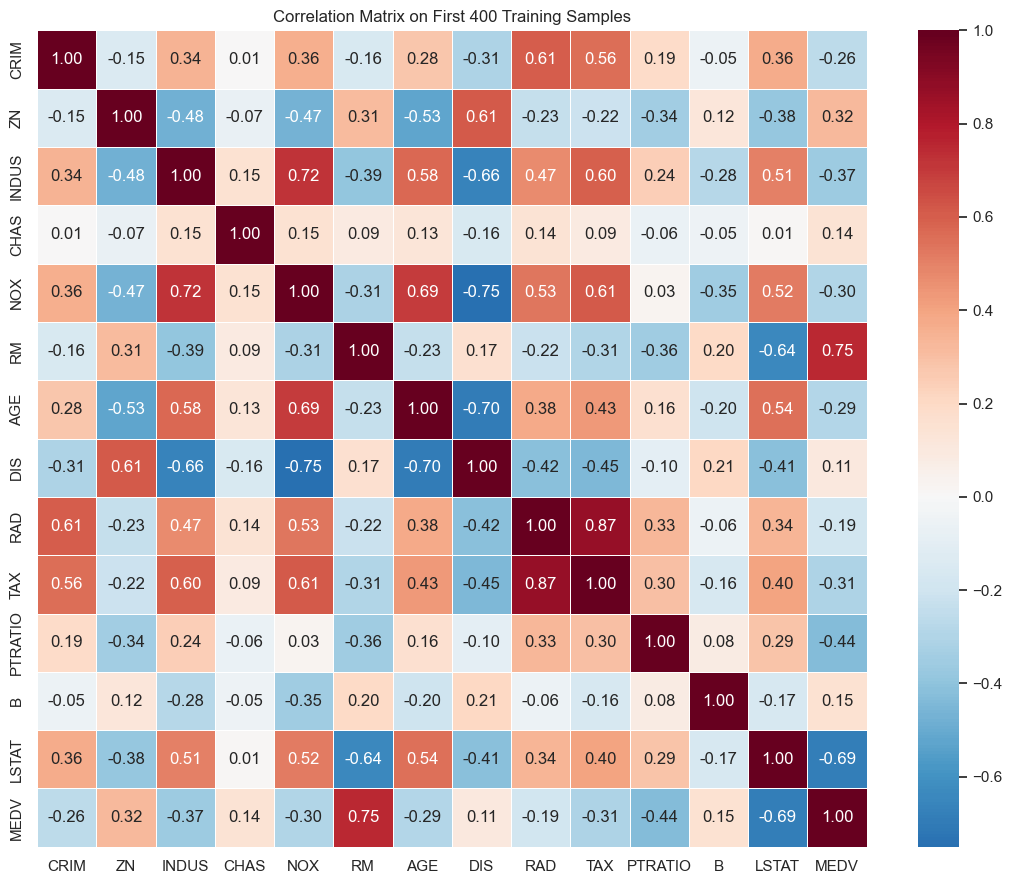

In [4]:
plt.figure(figsize=(11, 9))
sns.heatmap(train_df_for_eda.corr(numeric_only=True), cmap='RdBu_r', center=0, annot=True, fmt='.2f', linewidths=0.4)
plt.title('Correlation Matrix on First 400 Training Samples')
plt.tight_layout()
plt.show()

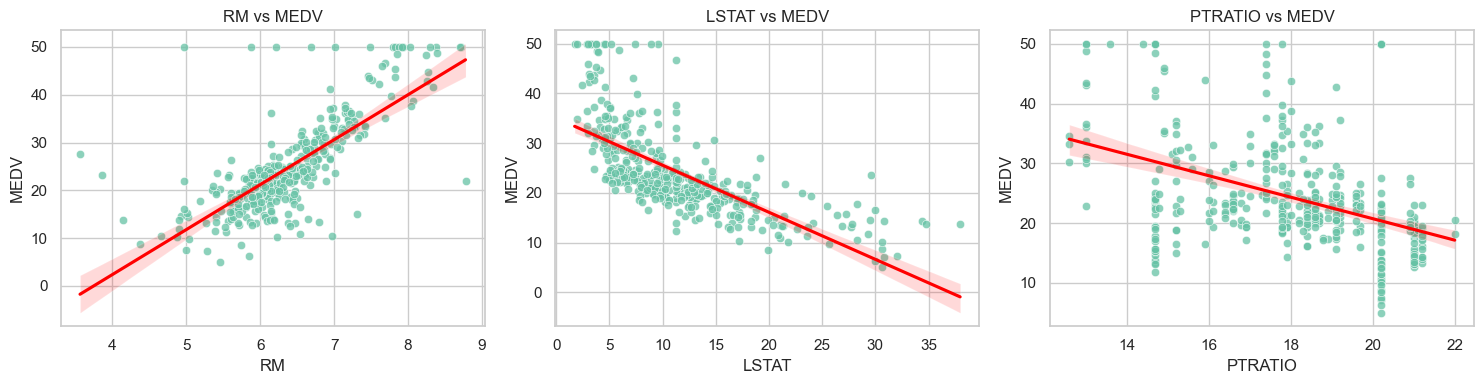

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, corr_top_features):
    sns.scatterplot(data=train_df_for_eda, x=feature, y=TARGET, ax=ax, alpha=0.75)
    sns.regplot(data=train_df_for_eda, x=feature, y=TARGET, ax=ax, scatter=False, color='red')
    ax.set_title(f'{feature} vs MEDV')
plt.tight_layout()
plt.show()

### 3.3 三特征组合尝试

为了回答“哪三个特征效果比较好”，这里保留两种训练阶段可以合理使用的尝试：

1. **相关性法**：选择训练集中与 `MEDV` 绝对相关性最高的 3 个特征；
2. **训练集交叉验证法**：在前 400 个训练样本内部，对所有三特征组合做 5 折交叉验证，选择平均 RMSE 最低的组合。

这两种方法都只使用训练集信息，不使用最后 100 个测试样本参与特征选择，因此更符合规范的建模流程。


In [6]:
def make_pipeline(model):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler()),
        ('model', model),
    ])

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 训练集内部交叉验证：先固定 Ridge(alpha=10)，快速比较所有三特征组合。
cv_feature_rows = []
for feature_combo in itertools.combinations(feature_names, 3):
    pipe = make_pipeline(Ridge(alpha=10.0))
    scores = cross_val_score(
        pipe,
        X_train_all[list(feature_combo)],
        y_train,
        cv=cv,
        scoring='neg_root_mean_squared_error'
    )
    cv_feature_rows.append({
        'features': feature_combo,
        'cv_rmse_mean': -scores.mean(),
        'cv_rmse_std': scores.std(),
    })

cv_feature_results = pd.DataFrame(cv_feature_rows).sort_values('cv_rmse_mean').reset_index(drop=True)
display(cv_feature_results.head(15))

cv_top_features = list(cv_feature_results.loc[0, 'features'])
print(f'训练集 5 折交叉验证最优三特征组合: {cv_top_features}')

,features,cv_rmse_mean,cv_rmse_std
0,"(RM, PTRATIO, LSTAT)",5.334623,0.923515
1,"(RM, DIS, LSTAT)",5.383295,0.895534
2,"(CHAS, RM, LSTAT)",5.441135,0.872492
3,"(NOX, RM, LSTAT)",5.488902,0.914051
4,"(RM, AGE, LSTAT)",5.499464,0.924549
5,"(RM, RAD, LSTAT)",5.505351,0.918549
6,"(INDUS, RM, LSTAT)",5.509359,0.919686
7,"(ZN, RM, LSTAT)",5.515029,0.908793
8,"(RM, B, LSTAT)",5.515975,0.917694
9,"(RM, TAX, LSTAT)",5.524105,0.924083


训练集 5 折交叉验证最优三特征组合: ['RM', 'PTRATIO', 'LSTAT']


## 4. 模型实现与参数调优

### 4.1 特征组合

两种特征选择方式得到的三个特征相同，因此后续建模固定使用这一组三特征：`RM`、`LSTAT`、`PTRATIO`。

- 相关性法得到：`RM`、`LSTAT`、`PTRATIO`；
- 训练集交叉验证法得到：`RM`、`PTRATIO`、`LSTAT`；
- 两者只是顺序不同，实际特征集合完全一致。

因此，后续不再比较不同特征组合，只比较不同线性模型及其正则化参数。


### 4.2 参数调优方法

固定三特征后，使用训练集 5 折交叉验证比较以下模型：普通线性回归、Ridge、Lasso 和 ElasticNet。调参只使用前 400 个训练样本，最后 100 个测试样本不参与模型选择，只用于最终评价。


In [7]:
selected_features = ['RM', 'LSTAT', 'PTRATIO']

print(f'最终固定使用的三个特征: {selected_features}')
print(f'相关性法特征: {corr_top_features}')
print(f'交叉验证法特征: {cv_top_features}')
print(f'两种方法得到的特征集合是否相同: {set(corr_top_features) == set(cv_top_features) == set(selected_features)}')

param_grid = [
    {'model': [LinearRegression()]},
    {'model': [Ridge()], 'model__alpha': [0.001, 0.01, 0.1, 1, 10, 100]},
    {'model': [Lasso(max_iter=20000, random_state=RANDOM_STATE)], 'model__alpha': [0.001, 0.01, 0.1, 1]},
    {'model': [ElasticNet(max_iter=20000, random_state=RANDOM_STATE)],
     'model__alpha': [0.001, 0.01, 0.1, 1],
     'model__l1_ratio': [0.2, 0.5, 0.8]},
]

def model_label(best_estimator):
    model = best_estimator.named_steps['model']
    if isinstance(model, LinearRegression):
        return 'LinearRegression'
    if isinstance(model, Ridge):
        return f'Ridge(alpha={model.alpha})'
    if isinstance(model, Lasso):
        return f'Lasso(alpha={model.alpha})'
    if isinstance(model, ElasticNet):
        return f'ElasticNet(alpha={model.alpha}, l1_ratio={model.l1_ratio})'
    return type(model).__name__

base_pipe = make_pipeline(Ridge())
grid = GridSearchCV(
    estimator=base_pipe,
    param_grid=param_grid,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    return_train_score=True,
    n_jobs=None,
)
grid.fit(X_train_all[selected_features], y_train)

best_model = grid.best_estimator_
cv_results_df = pd.DataFrame(grid.cv_results_).sort_values('rank_test_score').reset_index(drop=True)

model_comparison_df = cv_results_df[[
    'rank_test_score', 'mean_test_score', 'std_test_score',
    'param_model', 'param_model__alpha', 'param_model__l1_ratio'
]].head(12).copy()
model_comparison_df['cv_RMSE_mean'] = -model_comparison_df['mean_test_score']
model_comparison_df = model_comparison_df.drop(columns=['mean_test_score'])

display(model_comparison_df)
print(f'训练集交叉验证选择的最优模型: {model_label(best_model)}')
print(f'最优交叉验证 RMSE: {-grid.best_score_:.4f}')


最终固定使用的三个特征: ['RM', 'LSTAT', 'PTRATIO']
相关性法特征: ['RM', 'LSTAT', 'PTRATIO']
交叉验证法特征: ['RM', 'PTRATIO', 'LSTAT']
两种方法得到的特征集合是否相同: True


,rank_test_score,std_test_score,param_model,param_model__alpha,param_model__l1_ratio,cv_RMSE_mean
0,1,0.923515,Ridge(),10.000,NaN,5.334623
1,2,0.925396,"ElasticNet(max_iter=20000, random_state=42)",0.010,0.2,5.335462
2,3,0.925823,"ElasticNet(max_iter=20000, random_state=42)",0.010,0.5,5.335678
3,4,0.927793,"ElasticNet(max_iter=20000, random_state=42)",0.100,0.8,5.335719
4,5,0.926258,"ElasticNet(max_iter=20000, random_state=42)",0.010,0.8,5.335906
5,6,0.925779,Ridge(),1.000,NaN,5.335917
6,7,0.930395,"Lasso(max_iter=20000, random_state=42)",0.100,NaN,5.336042
7,8,0.926558,"Lasso(max_iter=20000, random_state=42)",0.010,NaN,5.336080
8,9,0.926042,"ElasticNet(max_iter=20000, random_state=42)",0.001,0.2,5.336151
9,10,0.926088,"ElasticNet(max_iter=20000, random_state=42)",0.001,0.5,5.336179


训练集交叉验证选择的最优模型: Ridge(alpha=10)
最优交叉验证 RMSE: 5.3346


In [8]:
# 使用最优模型分别在训练集和测试集上预测，并汇总评价指标。
y_train_pred = best_model.predict(X_train_all[selected_features])
y_test_pred = best_model.predict(X_test_all[selected_features])

metrics_df = pd.DataFrame([
    {
        'dataset': 'train_first_400',
        'RMSE': rmse_score(y_train, y_train_pred),
        'MAE': mean_absolute_error(y_train, y_train_pred),
        'R2': r2_score(y_train, y_train_pred),
    },
    {
        'dataset': 'test_last_100',
        'RMSE': rmse_score(y_test, y_test_pred),
        'MAE': mean_absolute_error(y_test, y_test_pred),
        'R2': r2_score(y_test, y_test_pred),
    },
])

display(metrics_df)


,dataset,RMSE,MAE,R2
0,train_first_400,5.317686,3.527756,0.662584
1,test_last_100,5.463824,4.478505,-0.165702


## 5. 实验结果与分析

### 5.1 模型评价指标

本实验使用以下指标：

- **RMSE**：均方根误差，越小越好，对大误差更敏感；
- **MAE**：平均绝对误差，越小越好，更容易解释为平均预测偏差；
- **R²**：决定系数，越接近 1 越好；若为负，说明模型还不如直接预测测试集均值。

### 5.2 模型性能比较

由于两种特征选择方式得到的三特征相同，本实验后续固定使用 `RM`、`LSTAT`、`PTRATIO`。模型性能比较的重点转为：在同一组三特征下，普通线性回归、Ridge、Lasso 和 ElasticNet 哪个模型及参数组合更优。

从交叉验证结果看，正则化模型能够在普通线性回归基础上提升稳定性。最终模型由训练集 5 折交叉验证确定，测试集只用于最终泛化性能评价。


In [9]:
# 固定使用训练集交叉验证得到的最优模型。
final_model = best_model
final_features = selected_features
final_pred = y_test_pred

final_result_df = pd.DataFrame({
    'sample_index': X_test_all.index,
    'actual_MEDV': y_test.values,
    'predicted_MEDV': final_pred,
    'residual': y_test.values - final_pred,
})

test_metrics = metrics_df[metrics_df['dataset'] == 'test_last_100'].iloc[0]

print('最终展示模型')
print(f'三个特征: {final_features}')
print(f'模型: {model_label(final_model)}')
print(f"训练集交叉验证 RMSE: {-grid.best_score_:.4f}")
print(f"测试集 RMSE: {test_metrics['RMSE']:.4f}")
print(f"测试集 MAE : {test_metrics['MAE']:.4f}")
print(f"测试集 R²  : {test_metrics['R2']:.4f}")

display(final_result_df.head(10))


最终展示模型
三个特征: ['RM', 'LSTAT', 'PTRATIO']
模型: Ridge(alpha=10)
训练集交叉验证 RMSE: 5.3346
测试集 RMSE: 5.4638
测试集 MAE : 4.4785
测试集 R²  : -0.1657


,sample_index,actual_MEDV,predicted_MEDV,residual
0,406,11.9,4.410363,7.489637
1,407,27.9,18.531756,9.368244
2,408,17.2,11.722562,5.477438
3,409,27.5,21.999540,5.500460
4,410,15.0,19.951988,-4.951988
5,411,17.2,20.197408,-2.997408
6,412,17.9,2.279471,15.620529
7,413,16.3,11.877013,4.422987
8,414,7.0,0.451521,6.548479
9,415,7.2,15.325555,-8.125555


In [10]:
# 查看最终模型系数，便于解释每个特征对 MEDV 的线性影响方向。
linear_part = final_model.named_steps['model']
coef_df = pd.DataFrame({
    'feature': final_features,
    'coefficient_after_standardization': linear_part.coef_,
}).sort_values('coefficient_after_standardization', key=lambda s: s.abs(), ascending=False)

print(f'截距: {linear_part.intercept_:.4f}')
display(coef_df)

截距: 24.3345


,feature,coefficient_after_standardization
0,RM,4.312188
1,LSTAT,-3.016284
2,PTRATIO,-1.532801


### 5.3 可视化分析

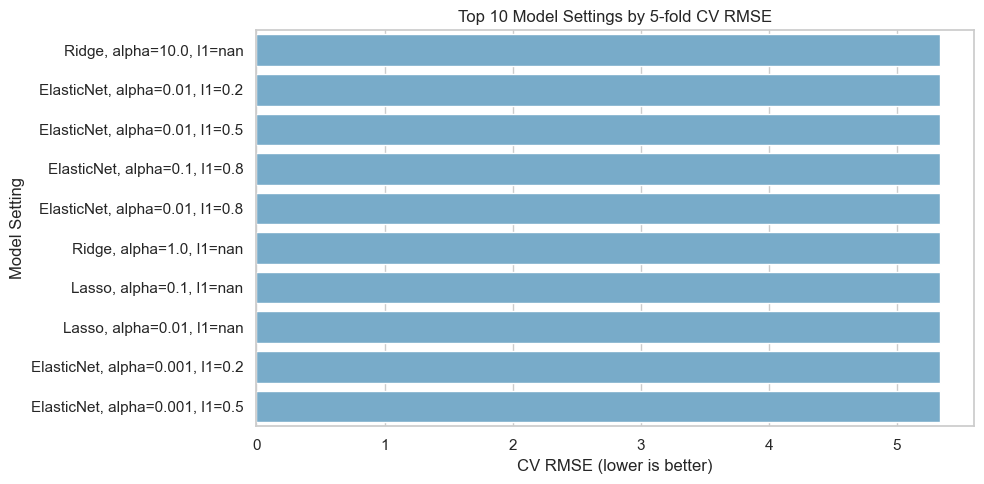

In [11]:
plt.figure(figsize=(10, 5))
plot_df = cv_results_df.head(10).copy()
plot_df['model_setting'] = plot_df.apply(
    lambda row: f"{type(row['param_model']).__name__}, alpha={row.get('param_model__alpha', '')}, l1={row.get('param_model__l1_ratio', '')}",
    axis=1
)
plot_df['cv_RMSE'] = -plot_df['mean_test_score']
sns.barplot(data=plot_df, x='cv_RMSE', y='model_setting', color='#6baed6')
plt.title('Top 10 Model Settings by 5-fold CV RMSE')
plt.xlabel('CV RMSE (lower is better)')
plt.ylabel('Model Setting')
plt.tight_layout()
plt.show()


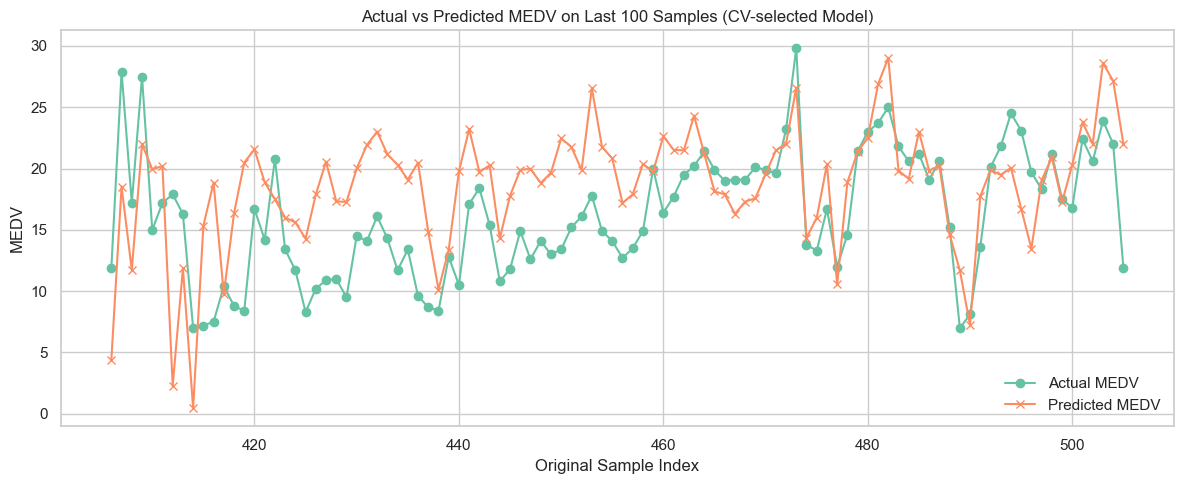

In [12]:
plt.figure(figsize=(12, 5))
plt.plot(final_result_df['sample_index'], final_result_df['actual_MEDV'], marker='o', label='Actual MEDV', linewidth=1.5)
plt.plot(final_result_df['sample_index'], final_result_df['predicted_MEDV'], marker='x', label='Predicted MEDV', linewidth=1.5)
plt.title('Actual vs Predicted MEDV on Last 100 Samples (CV-selected Model)')
plt.xlabel('Original Sample Index')
plt.ylabel('MEDV')
plt.legend()
plt.tight_layout()
plt.show()


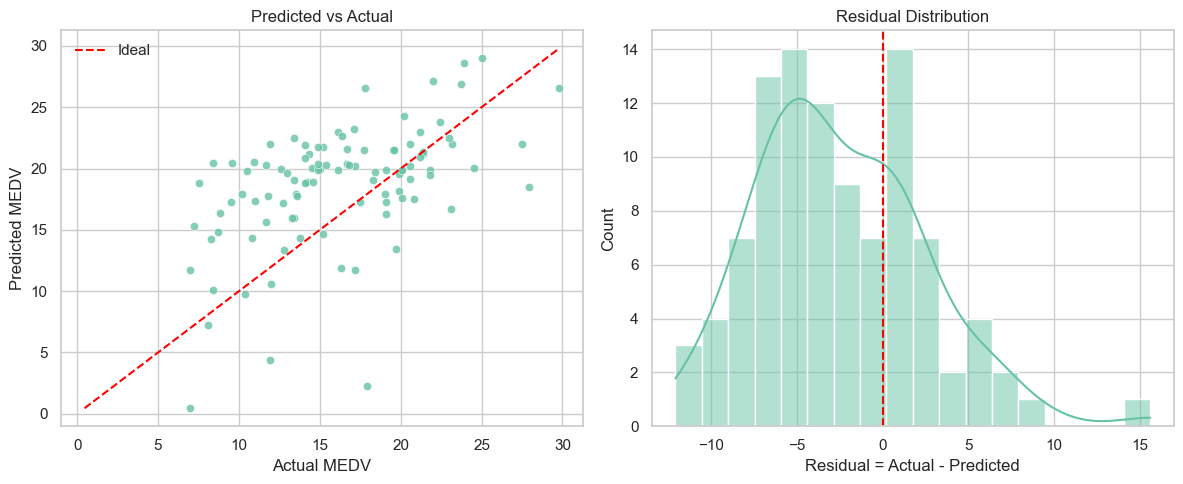

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(x=final_result_df['actual_MEDV'], y=final_result_df['predicted_MEDV'], ax=axes[0], alpha=0.8)
min_value = min(final_result_df['actual_MEDV'].min(), final_result_df['predicted_MEDV'].min())
max_value = max(final_result_df['actual_MEDV'].max(), final_result_df['predicted_MEDV'].max())
axes[0].plot([min_value, max_value], [min_value, max_value], color='red', linestyle='--', label='Ideal')
axes[0].set_title('Predicted vs Actual')
axes[0].set_xlabel('Actual MEDV')
axes[0].set_ylabel('Predicted MEDV')
axes[0].legend()

sns.histplot(final_result_df['residual'], bins=18, kde=True, ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title('Residual Distribution')
axes[1].set_xlabel('Residual = Actual - Predicted')

plt.tight_layout()
plt.show()

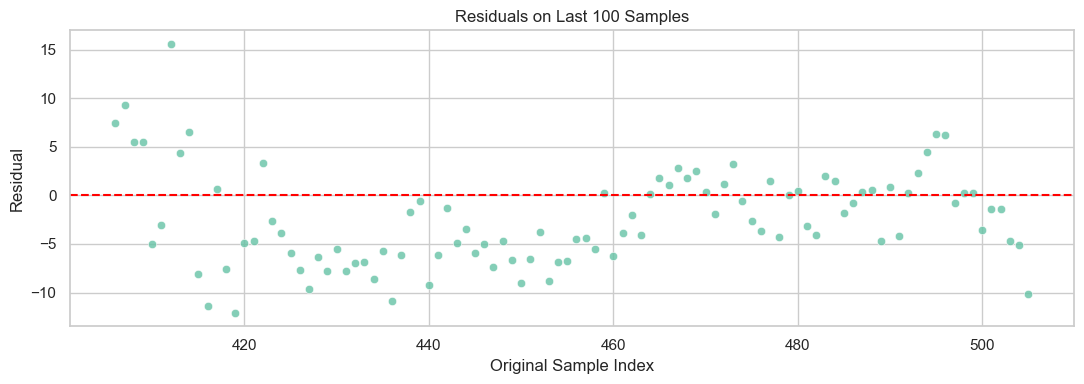

In [14]:
plt.figure(figsize=(11, 4))
sns.scatterplot(data=final_result_df, x='sample_index', y='residual', alpha=0.8)
plt.axhline(0, color='red', linestyle='--')
plt.title('Residuals on Last 100 Samples')
plt.xlabel('Original Sample Index')
plt.ylabel('Residual')
plt.tight_layout()
plt.show()

## 6. 结论与展望

### 6.1 实验结论

1. 相关性法和训练集交叉验证法最终得到相同的三个特征：`RM`、`LSTAT`、`PTRATIO`。
2. 因此，本实验将特征选择固定为这三个变量，后续重点比较不同线性回归模型和正则化参数。
3. 通过训练集 5 折交叉验证选择最终模型，测试集只用于最后评价，避免用测试集反向调参。
4. Ridge、Lasso、ElasticNet 都属于正则化线性模型，可以在普通线性回归基础上提高模型稳定性。
5. 最后 100 个样本的测试指标反映了模型在题目指定测试集上的泛化效果。

### 6.2 实验局限性与改进方向

1. 数据集按行切分而非随机切分，训练集和测试集分布可能存在差异，测试结果会受到样本排序影响。
2. 本实验只允许使用 3 个特征，模型表达能力有限，可能无法充分刻画房价与变量之间的复杂关系。
3. 当前只比较线性模型，后续可以尝试加入多项式特征、交叉项或非线性模型，但需要注意题目对特征数量和模型形式的限制。
4. 如果用于真实预测任务，应增加独立验证集或重复交叉验证，以获得更稳定的模型选择结论。
